# Predictive Power: Which Stats Help Us Predict?

**Predictive power** describes how much one piece of information helps us **guess** another.

Everyday examples:
- 🌧️ Dark clouds have **strong** predictive power for rain
- 👟 The colour of your shoes has **no** predictive power for rain

In netball, if we want to predict **how many goals a player scores**, which stats should we use?

In this notebook you will:
1. **See** predictive power with charts
2. **Measure** it with one number (correlation)
3. **Test** it with a machine learning model
4. Learn the **traps** to avoid

**How to run:** click a grey code cell and press **Shift + Enter**. Run the cells in order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

## Step 1: Make some pretend shooter data

We'll invent **60 shooters**. For each one we know:

| Column | Meaning |
| --- | --- |
| `attempts` | Shots taken per game |
| `training_hours` | Hours of shooting practice per week |
| `birth_month` | Month they were born (1 to 12) |
| `goals` | Goals per game, **the thing we want to predict** |

Can you guess which stat will be the **best** predictor of goals, and which will be **useless**?

You don't need to understand this cell. Just run it.

In [2]:
np.random.seed(7)
n = 60
attempts = np.random.randint(10, 60, n)
training_hours = np.random.randint(1, 10, n)
birth_month = np.random.randint(1, 13, n)
goals = (0.8 * attempts + 1.0 * training_hours + np.random.normal(0, 4, n)).round().clip(0)

players = pd.DataFrame({
    "attempts": attempts,
    "training_hours": training_hours,
    "birth_month": birth_month,
    "goals": goals,
})
players.head()

,attempts,training_hours,birth_month,goals
0,57,8,6,49.0
1,14,1,10,13.0
2,35,6,8,36.0
3,13,5,6,15.0
4,29,4,5,32.0


---
## Step 2: See it with charts

A **scatter plot** shows each player as a dot.

- Dots forming a **clear line** mean **strong** predictive power
- Dots in a **messy cloud** mean **weak or no** predictive power

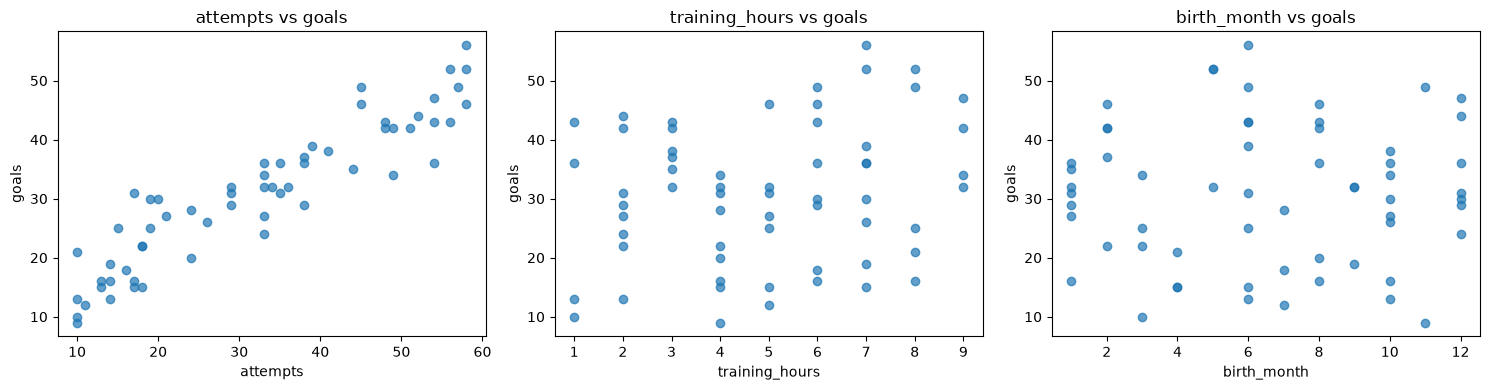

In [3]:
features = ["attempts", "training_hours", "birth_month"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, features):
    ax.scatter(players[feature], players["goals"], alpha=0.7)
    ax.set_xlabel(feature)
    ax.set_ylabel("goals")
    ax.set_title(f"{feature} vs goals")
plt.tight_layout()
plt.show()

**Think:**
- Which chart looks most like a line?
- Which chart looks like random dots?

---
## Step 3: Measure it with correlation

**Correlation** turns the pattern into **one number between -1 and 1**:

| Correlation | Meaning | What the dots look like |
| --- | --- | --- |
| close to **+1** | Strong: as one goes up, the other goes up | ↗ tight line |
| close to **0** | No link | ☁️ random cloud |
| close to **-1** | Strong: as one goes up, the other goes down | ↘ tight line |

> Rough guide: above 0.7 is **strong**, 0.3 to 0.7 is **medium**, below 0.3 is **weak**. The same applies to negative numbers.

In [5]:
correlations = players[features].corrwith(players["goals"]).round(2)
correlations

attempts          0.92
training_hours    0.21
birth_month       0.02
dtype: float64

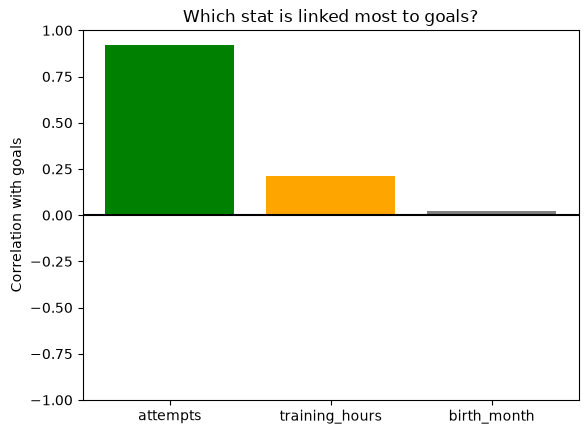

In [6]:
plt.bar(correlations.index, correlations.values, color=["green", "orange", "grey"])
plt.axhline(0, color="black")
plt.ylim(-1, 1)
plt.ylabel("Correlation with goals")
plt.title("Which stat is linked most to goals?")
plt.show()

---
## Step 4: Test it with machine learning

Correlation shows a link. The real test is whether a model can **predict players it has never seen**.

### The fair test
We split the players into two groups:
- **Training set (75%)**, which the model learns from
- **Test set (25%)**, kept hidden, like a surprise exam

Then we measure the model with **R²** (say "R squared"):

| R² | Meaning |
| --- | --- |
| **1.0** | Perfect predictions |
| **0.5** | Gets about half the pattern right |
| **0 or below** | No better than guessing the average every time |

In [7]:
train, test = train_test_split(players, test_size=0.25, random_state=1)

scores = {}
for feature in features:
    model = LinearRegression()
    model.fit(train[[feature]], train["goals"])
    scores[feature] = round(model.score(test[[feature]], test["goals"]), 2)

scores

{'attempts': 0.77, 'training_hours': -0.51, 'birth_month': -0.32}

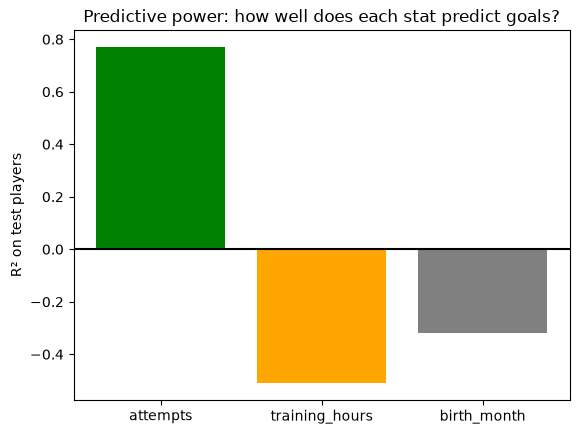

In [8]:
plt.bar(scores.keys(), scores.values(), color=["green", "orange", "grey"])
plt.axhline(0, color="black")
plt.ylabel("R² on test players")
plt.title("Predictive power: how well does each stat predict goals?")
plt.show()

### Predicted vs actual

Let's compare the **best** and the **worst** stat. If the predictions were perfect, every dot would sit on the red dashed line.

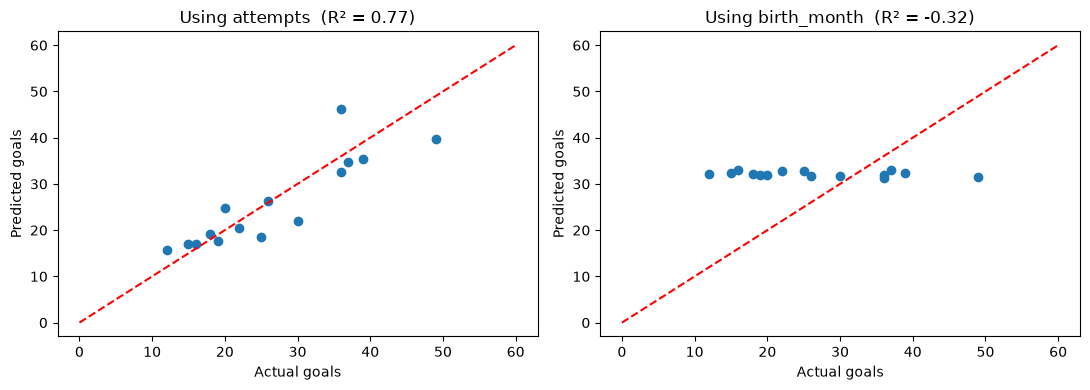

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, feature in zip(axes, ["attempts", "birth_month"]):
    model = LinearRegression().fit(train[[feature]], train["goals"])
    predicted = model.predict(test[[feature]])
    ax.scatter(test["goals"], predicted)
    ax.plot([0, 60], [0, 60], "r--")
    ax.set_xlabel("Actual goals")
    ax.set_ylabel("Predicted goals")
    ax.set_title(f"Using {feature}  (R² = {scores[feature]})")

plt.tight_layout()
plt.show()

**Think:** using `birth_month`, the model guesses about the same number for everyone. Why?

---
## Step 5: Teamwork. Combining stats

Stats can work **together**. Let's give the model both `attempts` **and** `training_hours`.

In [13]:
combo = ["attempts", "training_hours"]
model = LinearRegression().fit(train[combo], train["goals"])
print("R² using attempts only:          ", scores["attempts"])
print("R² using attempts + training:    ", round(model.score(test[combo], test["goals"]), 2))

R² using attempts only:           0.77
R² using attempts + training:     0.82


✏️ **Try it:** add `"birth_month"` to the `combo` list. Does it help? (Adding useless stats rarely helps.)

---
## Step 6: Traps to avoid ⚠️

### Trap 1: "Too good to be true" (cheating stats)
In the real data, `goals` = `one_pt_goals` + `super_shot_goals`. Using `one_pt_goals` to predict `goals` gives an amazing score, but it's **cheating**: you'd need to know the answer to make the prediction!

> Ask yourself: **would I know this stat *before* the thing I'm predicting happens?**

### Trap 2: Correlation is not causation
Ice cream sales and sunburn are strongly correlated, but ice cream doesn't **cause** sunburn. Sunny weather causes both.
In netball, players with more `minutes` have more of **everything**. That doesn't mean playing more minutes *causes* better skill.

### Trap 3: Small data can trick you
With only a few players, random patterns can look real. Watch it happen below.

In [14]:
few = players.sample(5, random_state=3)
print("Correlation of birth_month with goals using ALL 60 players:", round(players["birth_month"].corr(players["goals"]), 2))
print("Correlation of birth_month with goals using only 5 players:", round(few["birth_month"].corr(few["goals"]), 2))

Correlation of birth_month with goals using ALL 60 players: 0.02
Correlation of birth_month with goals using only 5 players: 0.73


Birth month is useless, but with only 5 players it can **look** like it matters. **More data = more trustworthy results.**

✏️ **Try it:** change `random_state=3` to other numbers and see how much the 5-player result jumps around.

---
## Step 7: Try it on the real netball data with AI (NSW EduChat)

The cell below is **working starter code** that uses the real data. It checks which defensive stats predict `gains`. Run it first, then use EduChat to help you **change it** to explore your own questions.

EduChat is a **tutor**. It won't write the code for you, but it **will guide you step by step** to change your code. That way you'll understand every line.

### 1. Start every new EduChat chat with this message

```
I'm a high school student at a netball data hack, new to Python. My pandas DataFrame df is loaded from SSN_2026_Player_Stats_Final.csv. Columns: position, team, minutes, goals, attempts, acc_pct, goal_assists, feeds, intercepts, deflections, gains, rebounds, penalties. Please guide me step by step to change my own code.
```

### 2. Prompts to copy

Copy a prompt, then paste your code from the starter cell underneath it.

**Check more stats**
```
This is my netball code. I want to check the correlation of every numeric column with gains, sorted highest to lowest. Can you guide me step by step?
```

**Turn it into a chart**
```
This is my netball code. I want to show the correlations as a bar chart instead of printing them. Can you guide me step by step?
```

**Predict something else**
```
This is my netball code. I want to find which stats best predict penalties instead of gains. Can you guide me step by step?
```

**Test it with ML** (also paste the Step 4 code from this notebook)
```
This is my netball code, and code that tests predictive power with LinearRegression and R². Can you guide me to use the R² method on my real data?
```

**Explain your result**
```
I predicted gains from deflections and got R² = 0.8, but from penalties R² = 0.3. Can you help me understand what this means?
```

> ⚠️ Remember **Trap 1**: don't predict `goals` from `one_pt_goals`, `super_shot_goals` or `acc_pct`, because they are part of the answer!

### 3. The conversation loop

EduChat will ask you questions. **That's how it works.** Each answer gets you one step closer.

1. **Paste** your code and say what you want to change
2. **Answer** EduChat's question. Have a go, even if you're unsure!
3. **Change** your code cell and **run it**
4. **Tell EduChat** what happened, then repeat until it's done

| If EduChat asks... | You can reply... |
| --- | --- |
| *"Which columns should we use?"* | Name them exactly: *"penalties, minutes and gains"* |
| *"Can you try rewriting this line?"* | Type your attempt: *"df[stats].corrwith(df["penalties"])"* |
| *"What do you think this line does?"* | Explain in your own words. A guess is fine! |
| You ran it and it worked | *"That worked! What's the next step?"* |
| You ran it and got an error | *"I changed it to ... and got this error: ... What should I check?"* |
| You've tried but you're stuck | *"I tried ... but I'm stuck. Can you give me a bigger hint?"* |
| It talks about the wrong sport or data | *"This is netball data. The columns are ..."* |

**Tips:**
- 📋 **Copy the cell first** so you keep a working version.
- 1️⃣ **Make one change at a time**, and run the code after every step.
- 🔄 **Going in circles?** Start a **new chat**, send the starter message, then your prompt.
- 🔒 **Never share personal information** in a chat.

Correlation with gains:
deflections    0.95
intercepts     0.92
penalties      0.88
dtype: float64


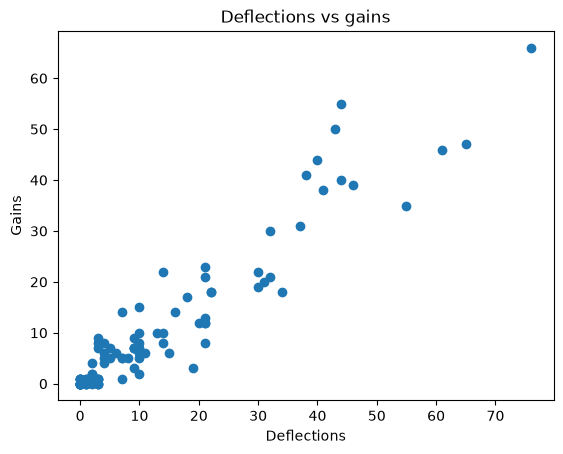

In [12]:
df = pd.read_csv("SSN_2026_Player_Stats_Final.csv")
df = df[df["minutes"] > 0]

stats = ["deflections", "intercepts", "penalties"]
correlations = df[stats].corrwith(df["gains"]).round(2)
print("Correlation with gains:")
print(correlations)

plt.scatter(df["deflections"], df["gains"])
plt.title("Deflections vs gains")
plt.xlabel("Deflections")
plt.ylabel("Gains")
plt.show()

---
## Summary

| Idea | What it means |
| --- | --- |
| **Predictive power** | How much a stat helps us guess something else |
| **Scatter plot** | *See* the link: a line is strong, a cloud is weak |
| **Correlation** (-1 to 1) | *Measure* the link with one number |
| **R² on test data** | *Test* if a model can predict new players |
| **Watch for traps** | Cheating stats, correlation ≠ causation, small data |

> **Big idea:** a good predictor is **linked** to the answer, **known before** the answer, and **tested** on data the model hasn't seen.